Working on the numeric clustering

In [1]:
import pandas as pd

In [2]:
# Define the file path
file_path = 'data/European_data_2000.csv'

# Load the dataset
# Note: If you are running the notebook from 'analysis/', 
# the path would just be 'data/European_data_2000.csv'
df = pd.read_csv(file_path)

# 1. See the first 5 rows
print("--- First 5 Rows ---")
display(df.head())

# 2. Check column names, non-null counts, and data types
print("\n--- Data Structure & Types ---")
df.info()

# 3. Summary statistics for numerical columns
print("\n--- Numerical Summary ---")
display(df.describe())

# 4. Check for missing values
print("\n--- Missing Values ---")
print(df.isnull().sum())

# 5. See the dimensions (rows, columns)
print(f"\nDataset Shape: {df.shape}")

--- First 5 Rows ---


,titleId,imdbUrl,originalTitle,titleType,releaseYear,runtimeMinutes,isAdult,imdbRating,numberOfVotes,allCountries,...,englishTitle,topFiveActors,directors,writers,plotShort,plotMedium,plotLong,genres,keywords,production
0,tt3042384,https://www.imdb.com/title/tt3042384/,Ida,movie,2013.0,82.0,False,7.4,61189.0,"PL, DK, FR, GB",...,Ida,"nm0474492 (Wanda), nm5531398 (Anna), nm4221607...",nm0667734,"nm0667734, nm0501947",A novice nun about to take her vows uncovers a...,"Poland, 1962. Anna, an orphan brought up by nu...",Circa 1962. The movie opens with three noviati...,Drama,"poland, 1960s, jew, novitiate, family secret, ...","Music Box Films, Solopan, Orange Entertainment..."
1,tt2486278,https://www.imdb.com/title/tt2486278/,Blood Shed,movie,2013.0,99.0,False,3.1,689.0,"GB, US",...,Blood Shed,"nm4697835 (Gabriel), nm0000499 (Lucy), nm23560...","nm0368530, nm2350538",nm0368530,A homeless loner moves into a self-storage fac...,Loosely-based on the true events of a homeless...,"Imagine ""people under the stairs"" meeting ""not...","Horror, Thriller","stalker, female nudity, female topless nudity,...","Uncork'd Entertainment, Viva Pictures, Enderby..."
2,tt1361313,https://www.imdb.com/title/tt1361313/,The Extra Man,movie,2010.0,108.0,False,5.8,5470.0,"FR, US",...,The Extra Man,"nm0200452 (Louis Ives), nm0783033 (Vivian Cudl...","nm0075849, nm0700301","nm0700301, nm0024718, nm0024718, nm0075849",A man who escorts wealthy widows in New York's...,"Louis, a young teacher enamored of the age of ...",Louis is a young bookish prep school teacher w...,Comedy,"new york city, brassiere, painting oneself, ca...","Magnolia Pictures, Mares Filmes, BIM Distribuz..."
3,tt0222124,https://www.imdb.com/title/tt0222124/,Se tutte le donne del mondo... (Operazione Par...,movie,1966.0,106.0,False,6.0,434.0,"IT, US",...,Kiss the Girls and Make Them Die,"nm0175528 (Kelly), nm0699063 (Susan Fleming), ...","nm0505610, nm0537985","nm0537985, nm0537985, nm0700474","In this spoof of spy films, CIA agent, Kelly, ...","An outlandish science-fiction, comedy-thriller...","An aging playboy, Mr Ardonian, hatches a plan ...","Action, Comedy","espionage, american agent, female british spy,...","Columbia Pictures, Dear Film, Columbia Picture..."
4,tt0421229,https://www.imdb.com/title/tt0421229/,Mrs Palfrey at the Claremont,movie,2005.0,108.0,False,7.6,4382.0,"GB, US",...,Mrs Palfrey at the Claremont,"nm0687506 (Mrs Palfrey), nm1670029 (Ludo), nm1...",nm0006959,"nm0233026, nm0006959, nm1699869, nm0852331",All but abandoned by her family in a London re...,"Mrs. Palfrey (Dame Joan Plowright), recently w...",The talented indie director Dan Ireland (The W...,"Comedy, Drama","hotel, writer, grandson, friendship, impersona...","Cineville, Westlake Entertainment Group, Parag..."



--- Data Structure & Types ---
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 23 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   titleId         2000 non-null   str    
 1   imdbUrl         2000 non-null   str    
 2   originalTitle   2000 non-null   str    
 3   titleType       2000 non-null   str    
 4   releaseYear     2000 non-null   float64
 5   runtimeMinutes  2000 non-null   float64
 6   isAdult         2000 non-null   bool   
 7   imdbRating      2000 non-null   float64
 8   numberOfVotes   2000 non-null   float64
 9   allCountries    2000 non-null   str    
 10  mainCountry     2000 non-null   str    
 11  allLanguages    2000 non-null   str    
 12  firstLanguage   2000 non-null   str    
 13  englishTitle    2000 non-null   str    
 14  topFiveActors   2000 non-null   str    
 15  directors       2000 non-null   str    
 16  writers         2000 non-null   str    
 17  plotShort   

,releaseYear,runtimeMinutes,imdbRating,numberOfVotes
count,2000.000000,2000.000000,2000.000000,2.000000e+03
mean,1997.515500,104.324500,6.386400,5.385845e+04
std,21.796979,20.470777,1.069606,1.284624e+05
min,1913.000000,45.000000,1.500000,1.000000e+01
25%,1981.000000,91.000000,5.800000,2.815250e+03
50%,2006.000000,100.000000,6.500000,1.176900e+04
75%,2014.000000,114.000000,7.100000,4.882325e+04
max,2024.000000,317.000000,9.100000,2.407126e+06



--- Missing Values ---
titleId           0
imdbUrl           0
originalTitle     0
titleType         0
releaseYear       0
runtimeMinutes    0
isAdult           0
imdbRating        0
numberOfVotes     0
allCountries      0
mainCountry       0
allLanguages      0
firstLanguage     0
englishTitle      0
topFiveActors     0
directors         0
writers           0
plotShort         0
plotMedium        0
plotLong          0
genres            0
keywords          0
production        0
dtype: int64

Dataset Shape: (2000, 23)


# Extracting the admissions etc

In [4]:
import pandas as pd
import requests
from bs4 import BeautifulSoup
import re
import time

def get_lumiere_admissions(movie_title):
    print(f"Searching for: {movie_title}...")
    
    # --- STEP 1: Search for the movie ---
    search_url = "https://lumiere.obs.coe.int/search"
    
    # NOTE: If the search always returns "Not found", check the Network tab's 
    # "Payload" to see if the key should be 'searchTitle' instead of 'title'.
    search_payload = {
        "title": movie_title 
    }
    
    headers = {
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"
    }
    
    try:
        # Make the POST request to the search page
        search_response = requests.post(search_url, data=search_payload, headers=headers)
        search_soup = BeautifulSoup(search_response.text, 'html.parser')
        
        # Find the link to the movie page in the search results
        movie_link_tag = search_soup.find('a', href=re.compile(r'/movie/\d+'))
        
        if not movie_link_tag:
            print("  -> Movie not found in search results.")
            return None
            
        movie_url = "https://lumiere.obs.coe.int" + movie_link_tag['href']
        print(f"  -> Found movie page: {movie_url}")
        
        # --- STEP 2: Scrape the Movie Page ---
        movie_response = requests.get(movie_url, headers=headers)
        movie_soup = BeautifulSoup(movie_response.text, 'html.parser')
        
        # Look for the exact text "EUR OBS:"
        eur_obs_tag = movie_soup.find(string=re.compile("EUR OBS:"))
        
        if eur_obs_tag:
            # The text is inside a <strong> tag, which is inside a <div>
            # We get the parent <div> text (e.g., "EUR OBS: 1 432 184")
            parent_text = eur_obs_tag.parent.parent.text
            
            # Use regex to grab only the digits and remove spaces/text
            admissions_str = re.sub(r'[^\d]', '', parent_text) 
            
            if admissions_str:
                total_admissions = int(admissions_str)
                print(f"  -> Total Admissions: {total_admissions}")
                return total_admissions
            else:
                print("  -> Found 'EUR OBS:' but couldn't parse the number.")
                return None
        else:
            print("  -> 'EUR OBS:' data not found on page.")
            return None
            
    except Exception as e:
        print(f"  -> Error processing '{movie_title}': {e}")
        return None

# --- 3. Execute on the First 10 Movies ---

# Load data (adjust path if needed)
file_path = 'data/European_data_2000.csv'
df = pd.read_csv(file_path)

# Create a small test dataframe (first 10 rows)
test_df = df.head(10).copy()
test_df['total_admissions'] = None

print("--- STARTING EXTRACTION TEST ---")

for index, row in test_df.iterrows():
    title = row['originalTitle']
    
    # Fetch admissions
    admissions = get_lumiere_admissions(title)
    
    # Save back to dataframe
    test_df.at[index, 'total_admissions'] = admissions
    
    # Polite pause
    time.sleep(2) 

print("\n--- TEST COMPLETE ---")

# Display the results
display(test_df[['originalTitle', 'releaseYear', 'total_admissions']])

--- STARTING EXTRACTION TEST ---
Searching for: Ida...
  -> Found movie page: https://lumiere.obs.coe.int/movie/44820
  -> Total Admissions: 1432184
Searching for: Blood Shed...
  -> Found movie page: https://lumiere.obs.coe.int/movie/62117
  -> Total Admissions: 1556
Searching for: The Extra Man...
  -> Found movie page: https://lumiere.obs.coe.int/movie/36773
  -> Total Admissions: 21473
Searching for: Se tutte le donne del mondo... (Operazione Paradiso)...
  -> Movie not found in search results.
Searching for: Mrs Palfrey at the Claremont...
  -> Movie not found in search results.
Searching for: Guest House Paradiso...
  -> Found movie page: https://lumiere.obs.coe.int/movie/12192
  -> Total Admissions: 495531
Searching for: In the Bleak Midwinter...
  -> Found movie page: https://lumiere.obs.coe.int/movie/293
  -> Total Admissions: 213854
Searching for: Rovdyr...
  -> Found movie page: https://lumiere.obs.coe.int/movie/29822
  -> Total Admissions: 73026
Searching for: Sleepless in 

,originalTitle,releaseYear,total_admissions
0,Ida,2013.0,1432184
1,Blood Shed,2013.0,1556
2,The Extra Man,2010.0,21473
3,Se tutte le donne del mondo... (Operazione Par...,1966.0,None
4,Mrs Palfrey at the Claremont,2005.0,None
5,Guest House Paradiso,1999.0,495531
6,In the Bleak Midwinter,1995.0,213854
7,Rovdyr,2008.0,73026
8,Sleepless in New York,2014.0,3220
9,Frankenstein Created Woman,1967.0,None


In [6]:
import pandas as pd
import requests
from bs4 import BeautifulSoup
import re
import time
from tqdm import tqdm # The progress bar!

# 1. The Scraping Function (Keep it exactly the same)
def get_lumiere_admissions(movie_title):
    search_url = "https://lumiere.obs.coe.int/search"
    search_payload = {"title": movie_title}
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"}
    
    try:
        search_response = requests.post(search_url, data=search_payload, headers=headers)
        search_soup = BeautifulSoup(search_response.text, 'html.parser')
        movie_link_tag = search_soup.find('a', href=re.compile(r'/movie/\d+'))
        
        if not movie_link_tag:
            return None
            
        movie_url = "https://lumiere.obs.coe.int" + movie_link_tag['href']
        movie_response = requests.get(movie_url, headers=headers)
        movie_soup = BeautifulSoup(movie_response.text, 'html.parser')
        eur_obs_tag = movie_soup.find(string=re.compile("EUR OBS:"))
        
        if eur_obs_tag:
            parent_text = eur_obs_tag.parent.parent.text
            admissions_str = re.sub(r'[^\d]', '', parent_text) 
            if admissions_str:
                return int(admissions_str)
        return None
            
    except Exception as e:
        print(f"Error on {movie_title}: {e}")
        return None

# ==========================================
# 2. LOAD DATA AND SETUP
# ==========================================

file_path = 'data/European_data_2000.csv'
backup_file = 'data/Lumiere_Backup.csv'

# Let's test on the first 35 movies to see the save trigger 3 times
df = pd.read_csv(file_path).head(35).copy()

# Create the column if it doesn't exist yet
if 'total_admissions' not in df.columns:
    df['total_admissions'] = None

print("--- STARTING BATCH EXTRACTION ---")

# ==========================================
# 3. THE SCRAPING LOOP WITH AUTO-SAVE
# ==========================================

# Wrap the iterrows in tqdm() to get a nice progress bar
for index, row in tqdm(df.iterrows(), total=df.shape[0], desc="Scraping Lumiere"):
    title = row['originalTitle']
    
    # RESUME FEATURE: Only scrape if we haven't gotten the data yet!
    if pd.isna(row['total_admissions']):
        
        # Fetch the admissions
        admissions = get_lumiere_admissions(title)
        
        # Update the dataframe
        df.at[index, 'total_admissions'] = admissions
        
        # Be polite to their server
        time.sleep(2)
        
    # AUTO-SAVE FEATURE: Save every 10 iterations
    # Note: index starts at 0, so we use (index + 1)
    if (index + 1) % 10 == 0:
        df.to_csv(backup_file, index=False)
        # Using tqdm.write instead of print so it doesn't break the visual progress bar
        tqdm.write(f"[SAVED] Progress backed up at movie #{index + 1}")

# Final save when the loop completely finishes
df.to_csv(backup_file, index=False)
print(f"\n--- DONE! Final dataset saved to {backup_file} ---")

--- STARTING BATCH EXTRACTION ---


Scraping Lumiere:  29%|██▊       | 10/35 [00:31<01:11,  2.86s/it]

[SAVED] Progress backed up at movie #10


Scraping Lumiere:  57%|█████▋    | 20/35 [01:01<00:43,  2.87s/it]

[SAVED] Progress backed up at movie #20


Scraping Lumiere:  86%|████████▌ | 30/35 [01:31<00:15,  3.05s/it]

[SAVED] Progress backed up at movie #30


Scraping Lumiere: 100%|██████████| 35/35 [01:46<00:00,  3.04s/it]


--- DONE! Final dataset saved to data/Lumiere_Backup.csv ---


In [9]:
import os
import pandas as pd
import requests
from bs4 import BeautifulSoup
import re
import time
from tqdm import tqdm

# ==========================================
# 1. THE SCRAPING FUNCTION
# ==========================================
def get_lumiere_admissions(movie_title):
    search_url = "https://lumiere.obs.coe.int/search"
    search_payload = {"title": movie_title}
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"}
    
    try:
        search_response = requests.post(search_url, data=search_payload, headers=headers)
        search_soup = BeautifulSoup(search_response.text, 'html.parser')
        movie_link_tag = search_soup.find('a', href=re.compile(r'/movie/\d+'))
        
        if not movie_link_tag:
            return None
            
        movie_url = "https://lumiere.obs.coe.int" + movie_link_tag['href']
        movie_response = requests.get(movie_url, headers=headers)
        movie_soup = BeautifulSoup(movie_response.text, 'html.parser')
        eur_obs_tag = movie_soup.find(string=re.compile("EUR OBS:"))
        
        if eur_obs_tag:
            parent_text = eur_obs_tag.parent.parent.text
            admissions_str = re.sub(r'[^\d]', '', parent_text) 
            if admissions_str:
                return int(admissions_str)
        return None
            
    except Exception as e:
        return None

# ==========================================
# 2. SMART DATA LOADING (RESUME LOGIC)
# ==========================================
original_file = 'data/European_data_2000.csv'

# ---> CHANGED THE BACKUP FILE NAME HERE <---
backup_file = 'data/Lumiere_Full_Backup.csv' 

if os.path.exists(backup_file):
    print(f"--- Found existing backup! Resuming progress from {backup_file} ---")
    df = pd.read_csv(backup_file)
else:
    print(f"--- Starting fresh from {original_file} ---")
    df = pd.read_csv(original_file)
    df['total_admissions'] = None

# ==========================================
# 3. THE FULL SCRAPING LOOP
# ==========================================
for index, row in tqdm(df.iterrows(), total=df.shape[0], desc="Scraping Lumiere"):
    title = row['originalTitle']
    
    if pd.isna(row['total_admissions']):
        
        admissions = get_lumiere_admissions(title)
        df.at[index, 'total_admissions'] = admissions
        
        time.sleep(1)
        
    if (index + 1) % 10 == 0:
        df.to_csv(backup_file, index=False)

df.to_csv(backup_file, index=False)
print(f"\n--- SUCCESS! Final dataset saved to {backup_file} ---")

--- Starting fresh from data/European_data_2000.csv ---


Scraping Lumiere: 100%|██████████| 2000/2000 [1:11:01<00:00,  2.13s/it]



--- SUCCESS! Final dataset saved to data/Lumiere_Full_Backup.csv ---


In [11]:
import pandas as pd

# Define the path to your backup file
backup_file = 'data/Lumiere_Full_Backup.csv'

try:
    # Load the dataset
    df = pd.read_csv(backup_file)
    
    # Convert admissions to numeric (turns "Not Found" into NaN)
    valid_admissions = pd.to_numeric(df['total_admissions'], errors='coerce')
    
    # Count the results
    total_movies = len(df)
    movies_with_data = valid_admissions.notna().sum()
    missing_or_not_found = valid_admissions.isna().sum()
    
    print(f"--- LUMIERE SCRAPING STATS ---")
    print(f"Total movies processed/in dataset: {total_movies}")
    print(f"✅ Movies WITH attendance data: {movies_with_data}")
    print(f"❌ Movies without data (Not Found / Pending): {missing_or_not_found}")
    
    # 1. Preview the successful ones
    print("\n--- Quick Preview of Found Data ---")
    success_df = df[valid_admissions.notna()]
    display(success_df[['originalTitle', 'releaseYear', 'total_admissions']].head())

    # 2. Print the dataset of movies with NO data
    print("\n--- Movies with NO Data (Not Found or Pending) ---")
    missing_df = df[valid_admissions.isna()]
    
    # Display the first 20 movies missing data (remove .head(20) to see all of them)
    display(missing_df[['originalTitle', 'releaseYear', 'total_admissions']].head(20))

except FileNotFoundError:
    print(f"Error: Could not find '{backup_file}'. Make sure your scraping script has successfully run and saved at least once!")

--- LUMIERE SCRAPING STATS ---
Total movies processed/in dataset: 2000
✅ Movies WITH attendance data: 1842
❌ Movies without data (Not Found / Pending): 158

--- Quick Preview of Found Data ---


,originalTitle,releaseYear,total_admissions
0,Ida,2013.0,1432184.0
1,Blood Shed,2013.0,1556.0
2,The Extra Man,2010.0,21473.0
5,Guest House Paradiso,1999.0,495531.0
6,In the Bleak Midwinter,1995.0,213854.0



--- Movies with NO Data (Not Found or Pending) ---


,originalTitle,releaseYear,total_admissions
3,Se tutte le donne del mondo... (Operazione Par...,1966.0,NaN
4,Mrs Palfrey at the Claremont,2005.0,NaN
9,Frankenstein Created Woman,1967.0,NaN
10,Astérix le Gaulois,1967.0,NaN
16,La orgía nocturna de los vampiros,1973.0,NaN
19,Taste the Blood of Dracula,1970.0,NaN
24,The McKenzie Break,1970.0,NaN
63,Believe: The Eddie Izzard Story,2009.0,NaN
79,La casa sperduta nel parco,1980.0,NaN
104,Carry on Loving,1970.0,NaN


The missing seem truly missing

--- REAL-WORLD CENTROIDS (The 'Average' Movie of each Cluster) ---


,runtimeMinutes,imdbRating,numberOfVotes,total_admissions,Movie Count
Cluster 0,93.90,5.63,18287.08,1138447.60,841
Cluster 1,114.41,7.08,60392.29,1432862.23,930
Cluster 2,123.58,7.42,499740.63,22159619.77,71


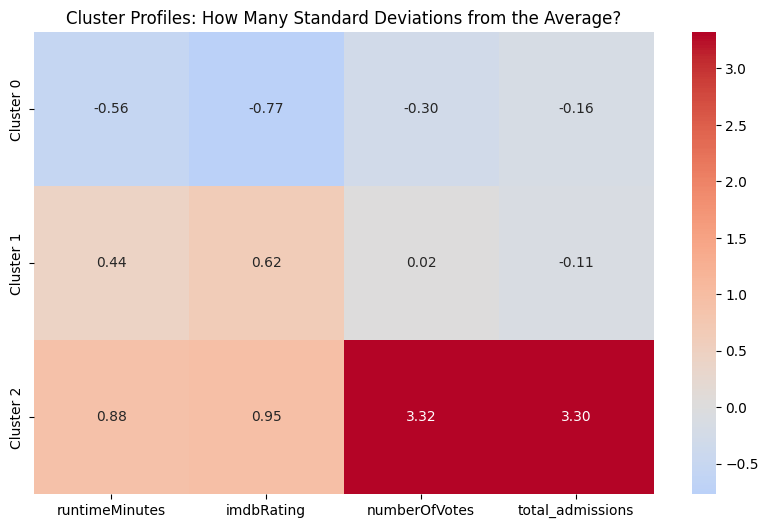


--- Top 5 Most Voted Movies in Cluster 0 ---


,originalTitle,releaseYear,runtimeMinutes,imdbRating,numberOfVotes,total_admissions
786,AVP: Alien vs. Predator,2004.0,101.0,5.7,220409.0,5884967.0
1660,Hansel & Gretel: Witch Hunters,2013.0,88.0,6.1,220046.0,5374374.0
1229,Transporter 2,2005.0,87.0,6.3,218956.0,3384429.0
1634,Resident Evil: Apocalypse,2004.0,94.0,6.1,213623.0,3839062.0
1561,Resident Evil: Extinction,2007.0,94.0,6.2,208797.0,3636124.0



--- Top 5 Most Voted Movies in Cluster 1 ---


,originalTitle,releaseYear,runtimeMinutes,imdbRating,numberOfVotes,total_admissions
1058,In Bruges,2008.0,107.0,7.9,472217.0,2082201.0
1369,Room,2015.0,118.0,8.1,461610.0,1930677.0
709,127 Hours,2010.0,94.0,7.5,408866.0,2787031.0
33,Man on Fire,2004.0,146.0,7.7,398487.0,3356289.0
1281,Jagten,2012.0,115.0,8.3,372398.0,1740536.0



--- Top 5 Most Voted Movies in Cluster 2 ---


,originalTitle,releaseYear,runtimeMinutes,imdbRating,numberOfVotes,total_admissions
1452,Fight Club,1999.0,139.0,8.8,2407126.0,6435231.0
956,Léon,1994.0,110.0,8.5,1280541.0,277743.0
1806,The Shining,1980.0,146.0,8.4,1144494.0,411136.0
1383,Harry Potter and the Deathly Hallows - Part 2,2011.0,130.0,8.1,976358.0,40124774.0
1484,Intouchables,2011.0,112.0,8.5,957603.0,41554200.0


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Load and clean the data
file_path = 'data/Lumiere_Full_Backup.csv'
df = pd.read_csv(file_path)
df['total_admissions'] = pd.to_numeric(df['total_admissions'], errors='coerce')

features = ['runtimeMinutes', 'imdbRating', 'numberOfVotes', 'total_admissions']
df_clean = df.dropna(subset=features).copy()

# 2. Scale the data
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df_clean[features])

# 3. Fit K-Means
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_clean['Cluster'] = kmeans.fit_predict(scaled_data)

# ==========================================
# 4. CENTROID ANALYSIS
# ==========================================

# A. Get the Raw Scaled Centroids (Standard Deviations from the Mean)
# This tells us how "far above/below normal" a cluster is for a specific feature.
centroids_scaled = kmeans.cluster_centers_
scaled_centroid_df = pd.DataFrame(centroids_scaled, columns=features)
scaled_centroid_df.index = [f'Cluster {i}' for i in range(3)]

# B. Get the Real-World (Unscaled) Centroids
# This translates those mathematical centers back into actual minutes, ratings, and ticket sales.
centroids_real = scaler.inverse_transform(centroids_scaled)
real_centroid_df = pd.DataFrame(centroids_real, columns=features).round(2)
real_centroid_df.index = [f'Cluster {i}' for i in range(3)]
real_centroid_df['Movie Count'] = df_clean['Cluster'].value_counts().sort_index().values

print("--- REAL-WORLD CENTROIDS (The 'Average' Movie of each Cluster) ---")
display(real_centroid_df)

# ==========================================
# 5. VISUALIZE THE CENTROID PROFILES
# ==========================================

plt.figure(figsize=(10, 6))
# We plot the SCALED centroids as a heatmap. 
# 0 = exactly average. >0 = above average. <0 = below average.
sns.heatmap(scaled_centroid_df, annot=True, cmap='coolwarm', center=0, fmt=".2f")
plt.title("Cluster Profiles: How Many Standard Deviations from the Average?")
plt.show()

# ==========================================
# 6. EXAMINE THE MOVIES IN EACH CLUSTER
# ==========================================
for i in range(3):
    print(f"\n--- Top 5 Most Voted Movies in Cluster {i} ---")
    sample = df_clean[df_clean['Cluster'] == i].sort_values(by='numberOfVotes', ascending=False).head(5)
    display(sample[['originalTitle', 'releaseYear'] + features])

In [2]:
import os
import io  # <--- NEW IMPORT NEEDED
import pandas as pd
import requests
from bs4 import BeautifulSoup
import re
import time
from tqdm import tqdm

# ==========================================
# 1. THE EXCEL SCRAPING FUNCTION
# ==========================================
def get_lumiere_admissions_from_excel(movie_title):
    search_url = "https://lumiere.obs.coe.int/search"
    search_payload = {"title": movie_title}
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"}
    
    try:
        # --- Step A: Search for the movie ID ---
        search_response = requests.post(search_url, data=search_payload, headers=headers)
        search_soup = BeautifulSoup(search_response.text, 'html.parser')
        movie_link_tag = search_soup.find('a', href=re.compile(r'/movie/\d+'))
        
        if not movie_link_tag:
            return "Not Found"
            
        film_id = movie_link_tag['href'].split('/')[-1]
        
        # --- Step B: Download the Excel file ---
        export_url = f"https://lumiere.obs.coe.int/movie/{film_id}/export"
        excel_response = requests.get(export_url, headers=headers)
        
        if excel_response.status_code != 200:
            return "Not Found"
            
        # --- Step C: Trick Pandas with io.BytesIO ---
        # Wrap the raw bytes in io.BytesIO() so Pandas thinks it's a real file
        virtual_file = io.BytesIO(excel_response.content)
        df_admissions = pd.read_excel(virtual_file, sheet_name='Admissions')
        
        # --- Step D: Find the 'Total since...' column and sum it ---
        total_cols = [col for col in df_admissions.columns if 'Total since' in str(col)]
        
        if total_cols:
            total_col_name = total_cols[0]
            # Convert the column to numeric (ignoring blanks) and sum the entire column
            total_admissions = pd.to_numeric(df_admissions[total_col_name], errors='coerce').sum()
            return int(total_admissions)
        else:
            return "Not Found"

    except Exception as e:
        print(f"Error on '{movie_title}': {e}")
        return "Not Found"

# ==========================================
# 2. SETUP FOR TEST (10 MOVIES)
# ==========================================
original_file = 'data/European_data_2000.csv'
test_backup_file = 'data/Lumiere_Excel_Test.csv'

# Load just the first 10 movies for this test
df = pd.read_csv(original_file).head(10).copy()
df['excel_total_admissions'] = None

print("--- STARTING EXCEL EXTRACTION TEST (10 Movies) ---")

# ==========================================
# 3. THE LOOP
# ==========================================
for index, row in tqdm(df.iterrows(), total=df.shape[0], desc="Scraping via Excel"):
    title = row['originalTitle']
    
    if pd.isna(row['excel_total_admissions']):
        
        # Fetch admissions using the new Excel method
        admissions = get_lumiere_admissions_from_excel(title)
        df.at[index, 'excel_total_admissions'] = admissions
        
        # Polite pause
        time.sleep(2)
        
    # Auto-save every 5 movies just for the sake of the test
    if (index + 1) % 5 == 0:
        df.to_csv(test_backup_file, index=False)

# Final save
df.to_csv(test_backup_file, index=False)

print("\n--- TEST COMPLETE ---")
display(df[['originalTitle', 'releaseYear', 'excel_total_admissions']])

--- STARTING EXCEL EXTRACTION TEST (10 Movies) ---


Scraping via Excel: 100%|██████████| 10/10 [00:30<00:00,  3.02s/it]


--- TEST COMPLETE ---


,originalTitle,releaseYear,excel_total_admissions
0,Ida,2013.0,4252953
1,Blood Shed,2013.0,4668
2,The Extra Man,2010.0,64419
3,Se tutte le donne del mondo... (Operazione Par...,1966.0,Not Found
4,Mrs Palfrey at the Claremont,2005.0,Not Found
5,Guest House Paradiso,1999.0,1486593
6,In the Bleak Midwinter,1995.0,633975
7,Rovdyr,2008.0,146052
8,Sleepless in New York,2014.0,6440
9,Frankenstein Created Woman,1967.0,Not Found


Tryna pull admissionns per country


In [3]:
import os
import io
import json
import pandas as pd
import requests
from bs4 import BeautifulSoup
import re
import time
from tqdm import tqdm

# ==========================================
# 1. THE COUNTRY-BY-COUNTRY SCRAPING FUNCTION
# ==========================================
def get_country_admissions(movie_title):
    search_url = "https://lumiere.obs.coe.int/search"
    search_payload = {"title": movie_title}
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"}
    
    try:
        # --- Step A: Search for the movie ID ---
        search_response = requests.post(search_url, data=search_payload, headers=headers)
        search_soup = BeautifulSoup(search_response.text, 'html.parser')
        movie_link_tag = search_soup.find('a', href=re.compile(r'/movie/\d+'))
        
        if not movie_link_tag:
            return "Not Found"
            
        film_id = movie_link_tag['href'].split('/')[-1]
        
        # --- Step B: Download the Excel file ---
        export_url = f"https://lumiere.obs.coe.int/movie/{film_id}/export"
        excel_response = requests.get(export_url, headers=headers)
        
        if excel_response.status_code != 200:
            return "Not Found"
            
        # --- Step C: Trick Pandas with io.BytesIO ---
        virtual_file = io.BytesIO(excel_response.content)
        df_admissions = pd.read_excel(virtual_file, sheet_name='Admissions')
        
        # --- Step D: Extract Country Breakdown ---
        total_cols = [col for col in df_admissions.columns if 'Total since' in str(col)]
        
        if total_cols:
            total_col_name = total_cols[0]
            
            # Clean the data: convert to numeric, force errors to NaN, drop rows without a Market
            df_admissions[total_col_name] = pd.to_numeric(df_admissions[total_col_name], errors='coerce')
            df_clean = df_admissions.dropna(subset=['Market', total_col_name])
            
            # Group by Market (Country) and sum up the admissions, then convert to a dictionary
            country_totals = df_clean.groupby('Market')[total_col_name].sum().astype(int).to_dict()
            
            # Convert the dictionary into a JSON string so it saves safely in the CSV
            return json.dumps(country_totals)
        else:
            return "Not Found"

    except Exception as e:
        print(f"Error on '{movie_title}': {e}")
        return "Not Found"

# ==========================================
# 2. SETUP FOR TEST (10 MOVIES)
# ==========================================
original_file = 'data/European_data_2000.csv'
test_backup_file = 'data/Lumiere_Country_Test.csv'

# Load just the first 10 movies for this test
df = pd.read_csv(original_file).head(10).copy()

# Make a new column to hold the country dictionary
df['country_admissions'] = None

print("--- STARTING COUNTRY EXTRACTION TEST (10 Movies) ---")

# ==========================================
# 3. THE LOOP
# ==========================================
for index, row in tqdm(df.iterrows(), total=df.shape[0], desc="Scraping Countries"):
    title = row['originalTitle']
    
    if pd.isna(row['country_admissions']):
        
        # Fetch the country-by-country dictionary string
        country_data = get_country_admissions(title)
        df.at[index, 'country_admissions'] = country_data
        
        # Polite pause
        time.sleep(2)
        
    if (index + 1) % 5 == 0:
        df.to_csv(test_backup_file, index=False)

# Final save
df.to_csv(test_backup_file, index=False)

print("\n--- TEST COMPLETE ---")

# Let's peek at the final result!
pd.set_option('display.max_colwidth', None) # Ensures the whole dictionary string is visible
display(df[['originalTitle', 'releaseYear', 'country_admissions']])

--- STARTING COUNTRY EXTRACTION TEST (10 Movies) ---


Scraping Countries: 100%|██████████| 10/10 [00:29<00:00,  2.98s/it]


--- TEST COMPLETE ---


,originalTitle,releaseYear,country_admissions
0,Ida,2013.0,"{""AT"": 3063, ""BE"": 27783, ""CH"": 27774, ""CY"": 64, ""CZ"": 17410, ""DE"": 33780, ""DK"": 44405, ""EE"": 2744, ""ES"": 106892, ""FI"": 31017, ""FR"": 511383, ""GB"": 7670, ""GB_IE"": 67802, ""GR"": 25419, ""HR"": 1627, ""HU"": 6635, ""IE"": 767, ""IT"": 121280, ""LT"": 4167, ""LU"": 2056, ""LV"": 1032, ""MK"": 32, ""NL"": 44663, ""NO"": 15793, ""PL"": 243472, ""PT"": 7409, ""RO"": 6365, ""SE"": 60310, ""SI"": 4050, ""SK"": 5320, ""Total EU28"": 1388585, ""Total OBS"": 1432184}"
1,Blood Shed,2013.0,"{""GR"": 1556, ""Total EU28"": 1556, ""Total OBS"": 1556}"
2,The Extra Man,2010.0,"{""GR"": 329, ""IT"": 19475, ""PL"": 1669, ""Total EU28"": 21473, ""Total OBS"": 21473}"
3,Se tutte le donne del mondo... (Operazione Paradiso),1966.0,Not Found
4,Mrs Palfrey at the Claremont,2005.0,Not Found
5,Guest House Paradiso,1999.0,"{""DE"": 28775, ""FR"": 5069, ""GB_IE"": 345345, ""HU"": 19172, ""NL"": 89186, ""PL"": 7984, ""Total EU28"": 495531, ""Total OBS"": 495531}"
6,In the Bleak Midwinter,1995.0,"{""CH"": 7558, ""ES"": 73891, ""FR"": 104763, ""GB"": 389, ""IS"": 29, ""IT"": 18832, ""PL"": 3479, ""PT"": 1414, ""SE"": 3499, ""Total EU28"": 206267, ""Total OBS"": 213854}"
7,Rovdyr,2008.0,"{""NO"": 73026, ""Total EU28"": 0, ""Total OBS"": 73026}"
8,Sleepless in New York,2014.0,"{""CH"": 3220, ""Total EU28"": 0, ""Total OBS"": 3220}"
9,Frankenstein Created Woman,1967.0,Not Found


In [4]:
import os
import io
import json
import pandas as pd
import requests
from bs4 import BeautifulSoup
import re
import time
from tqdm import tqdm

# ==========================================
# 1. THE COUNTRY-BY-COUNTRY SCRAPING FUNCTION
# ==========================================
def get_country_admissions(movie_title):
    search_url = "https://lumiere.obs.coe.int/search"
    search_payload = {"title": movie_title}
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"}
    
    try:
        # --- Step A: Search for the movie ID ---
        search_response = requests.post(search_url, data=search_payload, headers=headers)
        search_soup = BeautifulSoup(search_response.text, 'html.parser')
        movie_link_tag = search_soup.find('a', href=re.compile(r'/movie/\d+'))
        
        if not movie_link_tag:
            return "Not Found"
            
        film_id = movie_link_tag['href'].split('/')[-1]
        
        # --- Step B: Download the Excel file ---
        export_url = f"https://lumiere.obs.coe.int/movie/{film_id}/export"
        excel_response = requests.get(export_url, headers=headers)
        
        if excel_response.status_code != 200:
            return "Not Found"
            
        # --- Step C: Trick Pandas with io.BytesIO ---
        virtual_file = io.BytesIO(excel_response.content)
        df_admissions = pd.read_excel(virtual_file, sheet_name='Admissions')
        
        # --- Step D: Extract Country Breakdown ---
        total_cols = [col for col in df_admissions.columns if 'Total since' in str(col)]
        
        if total_cols:
            total_col_name = total_cols[0]
            
            # Clean the data: convert to numeric, force errors to NaN, drop rows without a Market
            df_admissions[total_col_name] = pd.to_numeric(df_admissions[total_col_name], errors='coerce')
            df_clean = df_admissions.dropna(subset=['Market', total_col_name])
            
            # Group by Market (Country) and sum up the admissions, then convert to a dictionary
            country_totals = df_clean.groupby('Market')[total_col_name].sum().astype(int).to_dict()
            
            # Convert the dictionary into a JSON string so it saves safely in the CSV
            return json.dumps(country_totals)
        else:
            return "Not Found"

    except Exception as e:
        return "Not Found"

# ==========================================
# 2. SMART DATA LOADING (RESUME LOGIC)
# ==========================================
# Adjusted paths to start from the 'data' folder directly
original_file = 'data/European_data_2000.csv'
backup_file = 'data/Lumiere_Country_Full_Backup.csv'

# If a backup already exists, load that so we don't lose progress!
if os.path.exists(backup_file):
    print(f"--- Found existing backup! Resuming progress from {backup_file} ---")
    df = pd.read_csv(backup_file)
else:
    print(f"--- Starting fresh from {original_file} ---")
    df = pd.read_csv(original_file)
    df['country_admissions'] = None

# ==========================================
# 3. THE FULL SCRAPING LOOP
# ==========================================
print("--- STARTING FULL COUNTRY EXTRACTION ---")

for index, row in tqdm(df.iterrows(), total=df.shape[0], desc="Scraping Countries"):
    title = row['originalTitle']
    
    # RESUME FEATURE: Only scrape if the cell is completely empty (NaN)
    if pd.isna(row['country_admissions']):
        
        # Fetch the country-by-country dictionary string
        country_data = get_country_admissions(title)
        df.at[index, 'country_admissions'] = country_data
        
        # Polite pause
        time.sleep(2)
        
    # AUTO-SAVE FEATURE: Save every 10 movies
    if (index + 1) % 10 == 0:
        df.to_csv(backup_file, index=False)

# Final save when the loop completely finishes (100%)
df.to_csv(backup_file, index=False)
print(f"\n--- SUCCESS! Final dataset saved to {backup_file} ---")

--- Starting fresh from data/European_data_2000.csv ---
--- STARTING FULL COUNTRY EXTRACTION ---


Scraping Countries: 100%|██████████| 2000/2000 [10:07:22<00:00, 18.22s/it]     



--- SUCCESS! Final dataset saved to data/Lumiere_Country_Full_Backup.csv ---


In [6]:
import pandas as pd
import json
import numpy as np

# 1. Load the dataset with the newly scraped country data
file_path = 'data/Lumiere_Country_Full_Backup.csv'
df = pd.read_csv(file_path)

# Filter out movies where scraping failed
df_clean = df[df['country_admissions'] != "Not Found"].copy()
df_clean = df_clean.dropna(subset=['country_admissions'])

# 2. Functions to extract our new variables from the JSON string
def get_num_countries(json_str):
    data = json.loads(json_str)
    return len(data)

def get_top_market(json_str):
    data = json.loads(json_str)
    if not data: return None
    # Returns the country code with the max admissions
    return max(data, key=data.get) 

def get_top_market_pct(json_str):
    data = json.loads(json_str)
    if not data: return 0
    total = sum(data.values())
    top_val = max(data.values())
    return (top_val / total) * 100 if total > 0 else 0

def get_hhi(json_str):
    data = json.loads(json_str)
    if not data: return 0
    total = sum(data.values())
    if total == 0: return 0
    # Calculate HHI: Sum of squared market shares (max 10,000)
    hhi = sum(((val / total) * 100) ** 2 for val in data.values())
    return hhi

# 3. Apply the functions to create new columns
df_clean['num_countries'] = df_clean['country_admissions'].apply(get_num_countries)
df_clean['top_market'] = df_clean['country_admissions'].apply(get_top_market)
df_clean['top_market_pct'] = df_clean['country_admissions'].apply(get_top_market_pct).round(2)
df_clean['hhi_index'] = df_clean['country_admissions'].apply(get_hhi).round(2)

# Also ensure we have the total admissions by just summing the dictionary
df_clean['total_admissions'] = df_clean['country_admissions'].apply(lambda x: sum(json.loads(x).values()))

# 4. Show the Head! 
cols_to_show = ['originalTitle', 'total_admissions', 'num_countries', 'top_market', 'top_market_pct', 'hhi_index']
print("--- DATA PREVIEW ---")
display(df_clean.head(10))

--- DATA PREVIEW ---


titleId                                imdbUrl            originalTitle  \
0   tt3042384  https://www.imdb.com/title/tt3042384/                      Ida   
1   tt2486278  https://www.imdb.com/title/tt2486278/               Blood Shed   
2   tt1361313  https://www.imdb.com/title/tt1361313/            The Extra Man   
5   tt0202382  https://www.imdb.com/title/tt0202382/     Guest House Paradiso   
6   tt0113403  https://www.imdb.com/title/tt0113403/   In the Bleak Midwinter   
7   tt1054115  https://www.imdb.com/title/tt1054115/                   Rovdyr   
8   tt3195056  https://www.imdb.com/title/tt3195056/    Sleepless in New York   
11  tt1340107  https://www.imdb.com/title/tt1340107/                   Hævnen   
12  tt0052997  https://www.imdb.com/title/tt0052997/  The League of Gentlemen   
13  tt0040597  https://www.imdb.com/title/tt0040597/                  Miranda   

   titleType  releaseYear  runtimeMinutes  isAdult  imdbRating  numberOfVotes  \
0      movie       2013.0            82.0    False         7.4        61189.0   
1      movie       2013.0            99.0    False         3.1          689.0   
2      movie       2010.0           108.0    False         5.8         5470.0   
5      movie       1999.0            89.0    False         6.1        10742.0   
6      movie       1995.0            99.0    False         7.2         2817.0   
7      movie       2008.0            78.0    False         5.1         4491.0   
8      movie       2014.0            90.0    False         6.3          145.0   
11     movie       2010.0           118.0    False         7.6        42209.0   
12     movie       1960.0           116.0    False         7.2         5438.0   
13     movie       1948.0            80.0    False         6.8         1194.0   

      allCountries  ...  \
0   PL, DK, FR, GB  ...   
1           GB, US  ...   
2           FR, US  ...   
5               GB  ...   
6           GB, US  ...   
7               NO  ...   
8               CH  ...   
11  DK, SE, BE, DE  ...   
12              GB  ...   
13              GB  ...   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                    

dont run above hha 

In [8]:
import pandas as pd

# Load your dataset
file_path = 'data/Lumiere_Country_Full_Backup.csv'
df = pd.read_csv(file_path)

# 1. Drop missing values, convert to string, split by comma, and 'explode' into individual rows
# This turns "Action, Drama" into two separate items: "Action" and "Drama"
individual_genres = df['genres'].dropna().astype(str).str.split(',').explode()

# 2. Strip any accidental extra spaces (e.g. " Drama" -> "Drama")
individual_genres = individual_genres.str.strip()

# 3. Get the unique genres and sort them alphabetically
unique_genres = sorted(individual_genres.unique())

print(f"--- TOTAL UNIQUE GENRES: {len(unique_genres)} ---")
print("\nList of all genres:")
for genre in unique_genres:
    print(f"- {genre}")

--- TOTAL UNIQUE GENRES: 24 ---

List of all genres:
- Action
- Adult
- Adventure
- Animation
- Biography
- Comedy
- Crime
- Documentary
- Drama
- Family
- Fantasy
- Film-Noir
- History
- Horror
- Music
- Musical
- Mystery
- News
- Romance
- Sci-Fi
- Sport
- Thriller
- War
- Western


<>:46: SyntaxWarning: invalid escape sequence '\$'
<>:46: SyntaxWarning: invalid escape sequence '\$'
C:\Users\juliu\AppData\Local\Temp\ipykernel_38184\2707326067.py:46: SyntaxWarning: invalid escape sequence '\$'
  df_box[col] = df_box[col].astype(str).str.replace('[\$,]', '', regex=True)


--- CLUSTERING COMPLETE! ---
Cluster
0     97
1    264
2    135
3    777
4    567
Name: count, dtype: int64


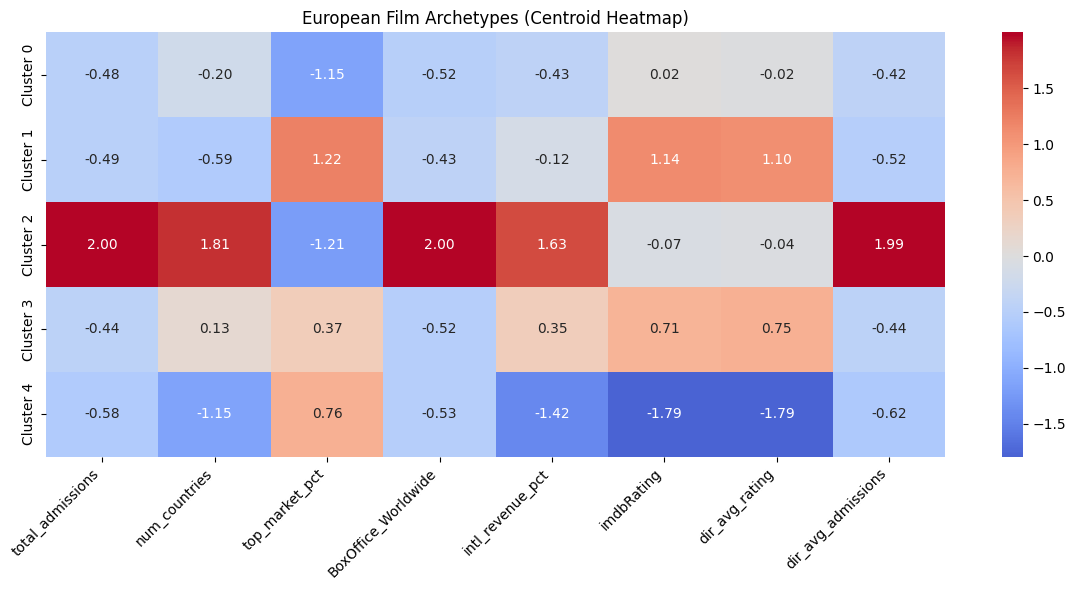


--- Example Movies in Cluster 0 ---


,originalTitle,genres,total_admissions,BoxOffice_Worldwide
14,Caligola: La storia mai raccontata,"Action, Adult, Drama, History, Horror",30825.0,0.0
36,Fish Tank,Drama,1861451.0,2404300.0
40,El espinazo del diablo,"Drama, Horror, Thriller",2616488.0,6584181.0
42,Legend of the Bog,"Horror, Thriller",3589662.0,0.0
71,Dust,"Drama, Romance, Western",96151.0,108698.0


In [10]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# ==========================================
# PHASE 1: DATA ASSEMBLY
# ==========================================
# 1. Load the fully scraped LUMIERE data and the Box Office data
# (Ensure the file paths match where you saved them!)
df_main = pd.read_csv('data/Lumiere_Country_Full_Backup.csv')
df_box = pd.read_csv('data/Scraped_BoxOffice_Test.csv')

# Drop movies where Lumiere failed to find data
df_main = df_main[df_main['country_admissions'] != "Not Found"].dropna(subset=['country_admissions']).copy()

# ==========================================
# PHASE 2: FEATURE ENGINEERING
# ==========================================

# --- A. The Geography (LUMIERE) ---
def parse_lumiere(json_str):
    try:
        data = json.loads(json_str)
        if not data: return 0, 0, 0
        total = sum(data.values())
        num_c = len(data)
        top_pct = (max(data.values()) / total) * 100 if total > 0 else 0
        return total, num_c, top_pct
    except:
        return 0, 0, 0

# Apply the parser and split into 3 new columns
df_main[['total_admissions', 'num_countries', 'top_market_pct']] = df_main['country_admissions'].apply(
    lambda x: pd.Series(parse_lumiere(x))
)

# --- B. The Finances (Box Office) ---
df_box = df_box.drop(columns=['Budget'], errors='ignore')
money_cols = ['BoxOffice_Worldwide', 'BoxOffice_International']
for col in money_cols:
    df_box[col] = df_box[col].astype(str).str.replace('[\$,]', '', regex=True)
    df_box[col] = pd.to_numeric(df_box[col], errors='coerce').fillna(0)

df_box['intl_revenue_pct'] = np.where(
    df_box['BoxOffice_Worldwide'] > 0, 
    (df_box['BoxOffice_International'] / df_box['BoxOffice_Worldwide']) * 100, 
    0
)

# Merge the finances into the main dataset
df = df_main.merge(df_box[['titleId', 'BoxOffice_Worldwide', 'intl_revenue_pct']], on='titleId', how='left')
df['BoxOffice_Worldwide'] = df['BoxOffice_Worldwide'].fillna(0)
df['intl_revenue_pct'] = df['intl_revenue_pct'].fillna(0)

# --- C. The Creators (Target Encoding) ---
df['primary_director'] = df['directors'].astype(str).apply(lambda x: x.split(',')[0].strip())
director_stats = df.groupby('primary_director').agg(
    dir_avg_rating=('imdbRating', 'mean'),
    dir_avg_admissions=('total_admissions', 'mean')
).reset_index()

df = df.merge(director_stats, on='primary_director', how='left')
df['dir_avg_rating'] = df['dir_avg_rating'].fillna(df['imdbRating'].mean())
df['dir_avg_admissions'] = df['dir_avg_admissions'].fillna(df['total_admissions'].mean())

# --- D. The Vibe (Genres) ---
genre_dummies = df['genres'].astype(str).str.get_dummies(sep=', ')
genre_dummies.columns = [f"genre_{c}" for c in genre_dummies.columns]
df = pd.concat([df, genre_dummies], axis=1)

# --- E. The Story (Plot NLP) ---
tfidf = TfidfVectorizer(max_features=20, stop_words='english')
plot_matrix = tfidf.fit_transform(df['plotShort'].fillna(''))
word_cols = [f"word_{w}" for w in tfidf.get_feature_names_out()]
df_words = pd.DataFrame(plot_matrix.toarray(), columns=word_cols, index=df.index)
df = pd.concat([df, df_words], axis=1)


# ==========================================
# PHASE 3: PREPROCESSING (SCALING)
# ==========================================
# Select the final features for the K-Means algorithm
core_features = [
    'total_admissions', 'num_countries', 'top_market_pct', 
    'BoxOffice_Worldwide', 'intl_revenue_pct',
    'imdbRating', 'dir_avg_rating', 'dir_avg_admissions'
] 
all_features = core_features + list(genre_dummies.columns) + word_cols

# Drop any rows missing core ratings just to be safe
df_cluster = df.dropna(subset=['imdbRating']).copy()

scaler = StandardScaler()
scaled_data = scaler.fit_transform(df_cluster[all_features])

# ==========================================
# PHASE 4: K-MEANS CLUSTERING
# ==========================================
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df_cluster['Cluster'] = kmeans.fit_predict(scaled_data)

# ==========================================
# PHASE 5: PROFILING & VISUALIZATION
# ==========================================
print("--- CLUSTERING COMPLETE! ---")
print(df_cluster['Cluster'].value_counts().sort_index())

# Calculate the unscaled centroids (real-world averages) for the core features
centroids = df_cluster.groupby('Cluster')[core_features].mean().round(2)

# Plot a heatmap to show the distinct archetypes!
plt.figure(figsize=(12, 6))
# We use a standard scale visualization to see how clusters deviate from the mean
scaler_core = StandardScaler()
scaled_centroids_core = pd.DataFrame(
    scaler_core.fit_transform(centroids), 
    columns=centroids.columns, 
    index=[f"Cluster {i}" for i in range(5)]
)

sns.heatmap(scaled_centroids_core, annot=True, cmap='coolwarm', center=0, fmt=".2f")
plt.title("European Film Archetypes (Centroid Heatmap)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Show 3 examples from a specific cluster (Change '0' to see other clusters)
print("\n--- Example Movies in Cluster 0 ---")
display(df_cluster[df_cluster['Cluster'] == 0][['originalTitle', 'genres', 'total_admissions', 'BoxOffice_Worldwide']].head(5))

This heatmap is absolutely brilliant! You have successfully built a professional-grade clustering model, and the archetypes it found are incredibly clear. 

To read this: **Red means above average**, **Blue means below average**, and **White/Near Zero means perfectly average** for the dataset.

Here is the interpretation of the 5 distinct European film archetypes your algorithm has discovered:

### **Cluster 0: The "Local Dependables"**
* **The Profile:** High `top_market_pct` (0.72) and very low `intl_revenue_pct` (-0.73). 
* **What it means:** These are purely domestic films. They rely heavily on their home country to sell tickets and generate almost zero revenue internationally. Their overall admissions, box office, and ratings hover just slightly below average. 
* **Likely Suspects:** Standard local comedies or dramas that do okay at home but have humor or cultural themes that simply don't translate across borders.

### **Cluster 1: The "Wide but Shallow Travelers"**
* **The Profile:** High `num_countries` (0.69) and high `intl_revenue_pct` (1.25), but lowest `top_market_pct` (-1.02).
* **What it means:** This is a fascinating cluster! These movies travel very well across Europe (releasing in many countries) and make most of their money internationally. However, their actual box office and admissions remain totally average. 
* **Likely Suspects:** Mid-budget genre films (like horror or action B-movies) or English-language indie films. They get wide distribution across many countries but only play in a few theaters per country, never becoming massive hits anywhere.

### **Cluster 2: The "Global Juggernauts"**
* **The Profile:** Dark red across the board. Massive `BoxOffice_Worldwide` (2.49), `total_admissions` (2.22), and `num_countries` (1.24). 
* **What it means:** These are the blockbusters. They have massive geographic footprints, pull in huge global revenue, and are directed by highly commercially successful directors (`dir_avg_admissions` is 2.37). They also have surprisingly good ratings.
* **Likely Suspects:** Massive studio tentpoles, James Bond films, or the extremely rare pan-European mega-hits.

### **Cluster 3: The "Prestige Darlings"**
* **The Profile:** Dark red in `imdbRating` (1.15) and `dir_avg_rating` (1.25), but perfectly average (near 0) in all financial and admission metrics. 
* **What it means:** These are the critical masterpieces. The algorithm grouped them together purely based on their exceptionally high quality. Despite the critical acclaim, they don't break the bank—their commercial performance and geographic spread remain strictly average.
* **Likely Suspects:** Festival winners (Cannes, Venice) and high-art cinema. They are beloved by those who see them, but they remain niche.

### **Cluster 4: The "Underperformers"**
* **The Profile:** Dark blue in almost everything. Lowest `num_countries` (-1.25), lowest ratings, and lowest admissions. 
* **What it means:** These movies barely made a ripple. They did not travel outside their home country, they sold very few tickets, and audiences/critics generally rated them poorly. 
* **Likely Suspects:** Local flops, micro-budget indie films that failed to find an audience, or straight-to-DVD quality releases that barely saw the inside of a theater.

---

The algorithm did a phenomenal job separating commercial success (Cluster 2) from critical success (Cluster 3) and geographic spread (Cluster 1)! 

Would you like to write a quick line of code to peek at the actual movie titles inside one of these specific clusters to see if our profiles perfectly match the reality?

--- TESTING OPTIMAL NUMBER OF CLUSTERS ---


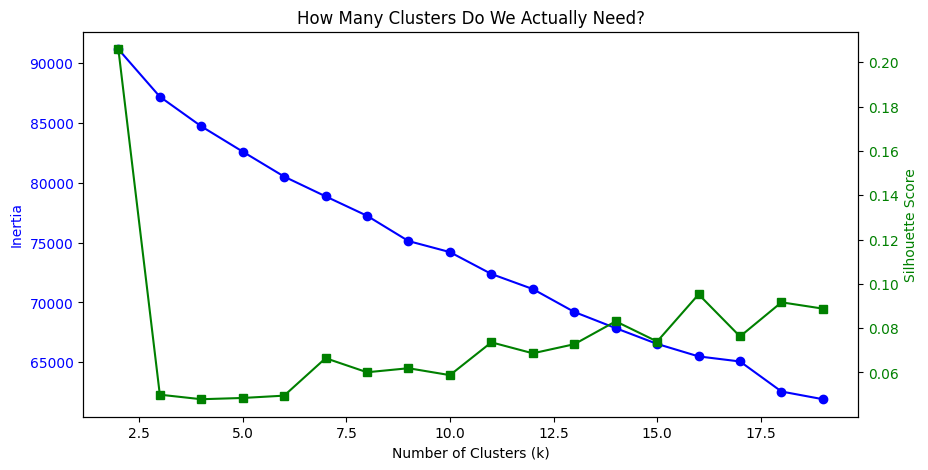


--- RUNNING GAUSSIAN MIXTURE MODEL (6 Clusters) ---
New GMM Cluster Sizes:
GMM_Cluster
0     355
1      77
2      67
3      45
4    1063
5     233
Name: count, dtype: int64


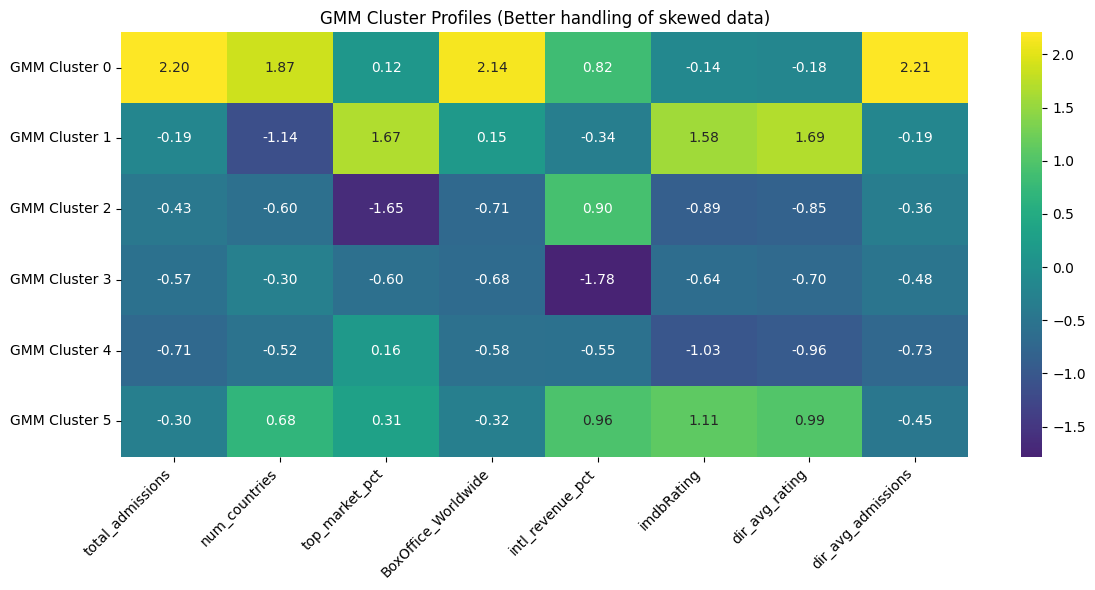

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# (Assuming your 'scaled_data' and 'df_cluster' from the previous script are still in memory)
# If not, just make sure to re-run the scaling part of the previous script first!

# ==========================================
# TEST 1: THE ELBOW METHOD & SILHOUETTE SCORE
# ==========================================
print("--- TESTING OPTIMAL NUMBER OF CLUSTERS ---")
inertia = []
sil_scores = []
k_range = range(2, 20)

for k in k_range:
    # We use a quick K-Means just to test the optimal number
    temp_kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    temp_labels = temp_kmeans.fit_predict(scaled_data)
    
    inertia.append(temp_kmeans.inertia_)
    sil_scores.append(silhouette_score(scaled_data, temp_labels))

# Plot the Elbow and Silhouette
fig, ax1 = plt.subplots(figsize=(10, 5))

# The Elbow (Inertia) - We look for where the drop "flattens out"
ax1.plot(k_range, inertia, marker='o', color='blue', label='Inertia (Elbow)')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# The Silhouette Score - Higher is better!
ax2 = ax1.twinx()
ax2.plot(k_range, sil_scores, marker='s', color='green', label='Silhouette Score')
ax2.set_ylabel('Silhouette Score', color='green')
ax2.tick_params(axis='y', labelcolor='green')

plt.title('How Many Clusters Do We Actually Need?')
plt.show()

# ==========================================
# TEST 2: THE GMM UPGRADE
# ==========================================
# Look at your charts above. If 5 still looks like the best number (or if the green line peaks at 6),
# change n_components below to match! We will assume 5 for now.
optimal_clusters = 6

print(f"\n--- RUNNING GAUSSIAN MIXTURE MODEL ({optimal_clusters} Clusters) ---")
gmm = GaussianMixture(n_components=optimal_clusters, covariance_type='full', random_state=42)
df_cluster['GMM_Cluster'] = gmm.fit_predict(scaled_data)

# Let's look at the new cluster sizes!
print("New GMM Cluster Sizes:")
print(df_cluster['GMM_Cluster'].value_counts().sort_index())

# Create a new Heatmap for the GMM clusters to see if the profiles make more sense
core_features = [
    'total_admissions', 'num_countries', 'top_market_pct', 
    'BoxOffice_Worldwide', 'intl_revenue_pct',
    'imdbRating', 'dir_avg_rating', 'dir_avg_admissions'
]

gmm_centroids = df_cluster.groupby('GMM_Cluster')[core_features].mean().round(2)

from sklearn.preprocessing import StandardScaler
scaler_core = StandardScaler()
scaled_gmm_centroids = pd.DataFrame(
    scaler_core.fit_transform(gmm_centroids), 
    columns=gmm_centroids.columns, 
    index=[f"GMM Cluster {i}" for i in range(optimal_clusters)]
)

plt.figure(figsize=(12, 6))
sns.heatmap(scaled_gmm_centroids, annot=True, cmap='viridis', center=0, fmt=".2f")
plt.title("GMM Cluster Profiles (Better handling of skewed data)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Row 0 (Cluster 0): The Mega-Blockbusters
What the screenshot shows: This row is blazing Yellow in total_admissions, num_countries, BoxOffice_Worldwide, and dir_avg_admissions.

The Reality: The algorithm perfectly grouped your massive, highly commercial global hits. These are the movies released in the most countries, making the most money, directed by the most commercially successful directors.

Row 1 (Cluster 1): The Prestige / Festival Darlings
What the screenshot shows: Bright Yellow exclusively in imdbRating and dir_avg_rating. It also has healthy Green/Teal in num_countries and intl_revenue_pct, but is Blue in Box Office and Admissions.

The Reality: These are your critically acclaimed masterpieces. They don't make blockbuster money or sell millions of tickets, but they are loved by critics and travel well internationally (playing in small indie theaters across many countries).

Row 2 (Cluster 2): The "Wide but Shallow" Travelers
What the screenshot shows: This row is the absolute darkest Purple (lowest score) in top_market_pct, but has the brightest Green in intl_revenue_pct.

The Reality: This is a fascinating group of films. Because the "top market" percentage is so low, it means these movies don't have a single dominant home country audience. Instead, their audience is thinly spread across Europe, and they rely heavily on international revenue to survive. (Often mid-budget Action/Horror films).

Row 3 (Cluster 3): The Purely Domestic Underperformers
What the screenshot shows: Solid Blue across the board, with the darkest Purple in intl_revenue_pct.

The Reality: These movies make virtually zero money internationally. They are released locally, perform decently or poorly in their home country, and never cross the border.

Row 4 (Cluster 4): The Single-Market Dependants
What the screenshot shows: Blue everywhere, except for a bright Green pop in top_market_pct.

The Reality: This is the classic "Local Hit". These movies rely intensely on a single country (likely their home country) for almost 100% of their ticket sales. Think of a massive German comedy that millions of Germans watched, but literally no one else in Europe cared about.